In [2]:
# Imports necesarios para el análisis
import zipfile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, pearsonr, probplot
from IPython.display import display
sns.set(style="whitegrid")

In [3]:
# Part 1: Analyzing Best-Seller Trends Across Product Categories
# Objective: Understand the relationship between product categories and their best-seller status.
import pandas as pd
import matplotlib.pyplot as plt
# Load the dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
# 1) Crosstab Analysis:
#    - Create a crosstab between the product `category` and the `isBestSeller` status.
#    - Are there categories where being a best-seller is more prevalent?
#      Hint: calculate the proportion of best-sellers for each category and sort descending.

ct = pd.crosstab(df['category'], df['isBestSeller'])
print(ct)


isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [10]:
#Proporcion of bestsellers by category
proportions = (
    pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
    .rename(columns={0: 'not_best_seller', 1: 'best_seller'})
)

proportions['best_seller_pct'] = proportions['best_seller'] * 100

# Ordenar y redondear a 2 decimales
proportions = proportions.sort_values(by='best_seller_pct', ascending=False)
proportions = proportions.round(2)

display(proportions)

isBestSeller,not_best_seller,best_seller,best_seller_pct
category,,,
Grocery,0.94,0.06,5.81
Smart Home Security & Lighting,0.94,0.06,5.77
Health & Personal Care,0.94,0.06,5.77
Mobile Phone Accessories,0.96,0.04,4.25
Power & Hand Tools,0.96,0.04,3.53
...,...,...,...
Bedding Collections,1.00,0.00,0.00
CPUs,1.00,0.00,0.00
"CD, Disc & Tape Players",1.00,0.00,0.00


Grocery, smart home and health&personal care are the categories with best-seller % more prevalent

In [7]:
!python -m pip install scipy


In [12]:
# 2) Statistical Tests:
#    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
#    - Compute Cramér's V to understand the strength of association between best-seller status and category.

# Test Chi-cuadrado
chi2, p, dof, expected = chi2_contingency(ct)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

# Cramér's V
n = ct.to_numpy().sum()
r, k = ct.shape
cramers_v = np.sqrt(chi2 / (n * (min(r - 1, k - 1))))

print("Cramér’s V:", cramers_v)



Chi-square: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295
Cramér’s V: 0.1222829439760564


The Chi-square test shows a statistically significant relationship between product category and best-seller status (p < 0.05), indicating that the two variables are not independent.
However, the Cramér’s V value of 0.12 indicates that the strength of this association is weak.
In practice, this means that although some categories exhibit a higher proportion of best-sellers, category alone is not a strong predictor of commercial success; additional variables such as price, rating, or number of reviews are required to better explain the phenomenon

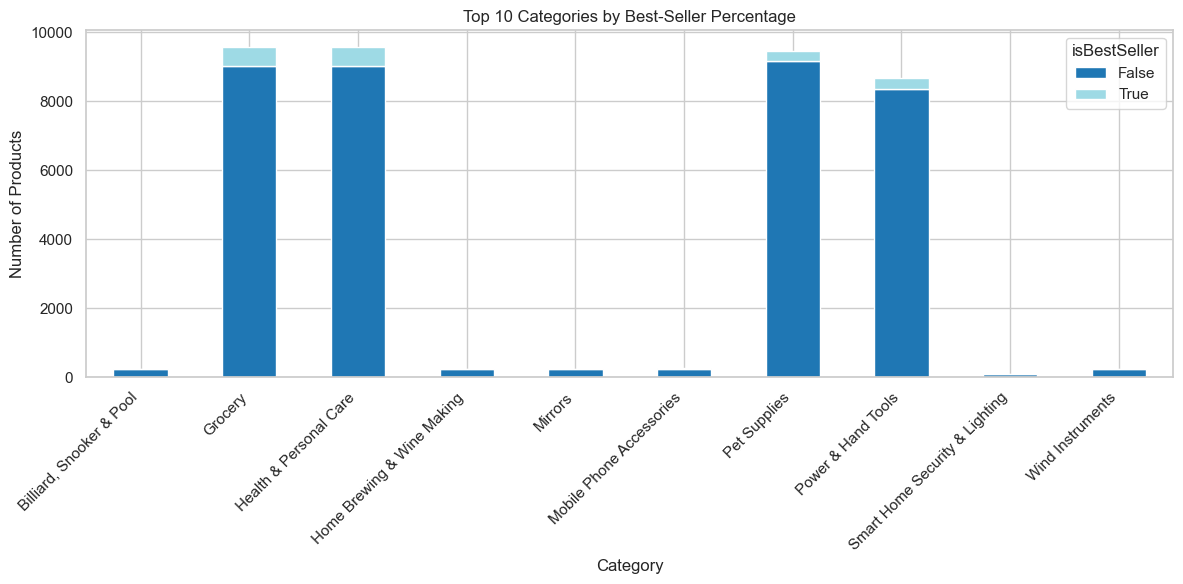

In [13]:
# 3) Visualizations:
#    - Visualize the relationship using a stacked bar chart of `category` vs `isBestSeller`.
# Seleccionar las top 10 categorías con mayor % de best-sellers

top10 = proportions.sort_values('best_seller_pct', ascending=False).head(10)
top10
contingency_top10 = pd.crosstab(
    df[df['category'].isin(top10.index)]['category'],
    df['isBestSeller']
)
contingency_top10.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    colormap='tab20'
)
plt.title("Top 10 Categories by Best-Seller Percentage")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [18]:
#Part2: Preliminary Step: Remove outliers in product prices using the IQR method.
#    - Products below Q1 - 1.5*IQR or above Q3 + 1.5*IQR are outliers.
# 1) Violin Plots:
#    - Visualize the distribution of `price` across product `categories`.
#    - Filter out the top 20 categories based on count for better visualization.
#    - Which category tends to have the highest median price? (No top filter here.)

# Calcular IQR y filtrar outliers
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df_filtered = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Q1 (25th percentile): {Q1:.2f}")
print(f"Q3 (75th percentile): {Q3:.2f}")
print(f"IQR (Q3 - Q1): {IQR:.2f}")
print(f"Lower bound (Q1 - 1.5*IQR): {lower_bound:.2f}")
print(f"Upper bound (Q3 + 1.5*IQR): {upper_bound:.2f}")

#Filtrando outliers

print(f"Original number of observations: {len(df)}")
print(f"Number of observations after outlier removal: {len(df_filtered)}")
print(f"Number of outliers removed: {len(df) - len(df_filtered)}")

Q1 (25th percentile): 9.99
Q3 (75th percentile): 45.99
IQR (Q3 - Q1): 36.00
Lower bound (Q1 - 1.5*IQR): -44.01
Upper bound (Q3 + 1.5*IQR): 99.99
Original number of observations: 2443651
Number of observations after outlier removal: 2115963
Number of outliers removed: 327688


C:\Users\marta\AppData\Local\Temp\ipykernel_22600\279482294.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='category', y='price', data=df_top20, palette='muted')


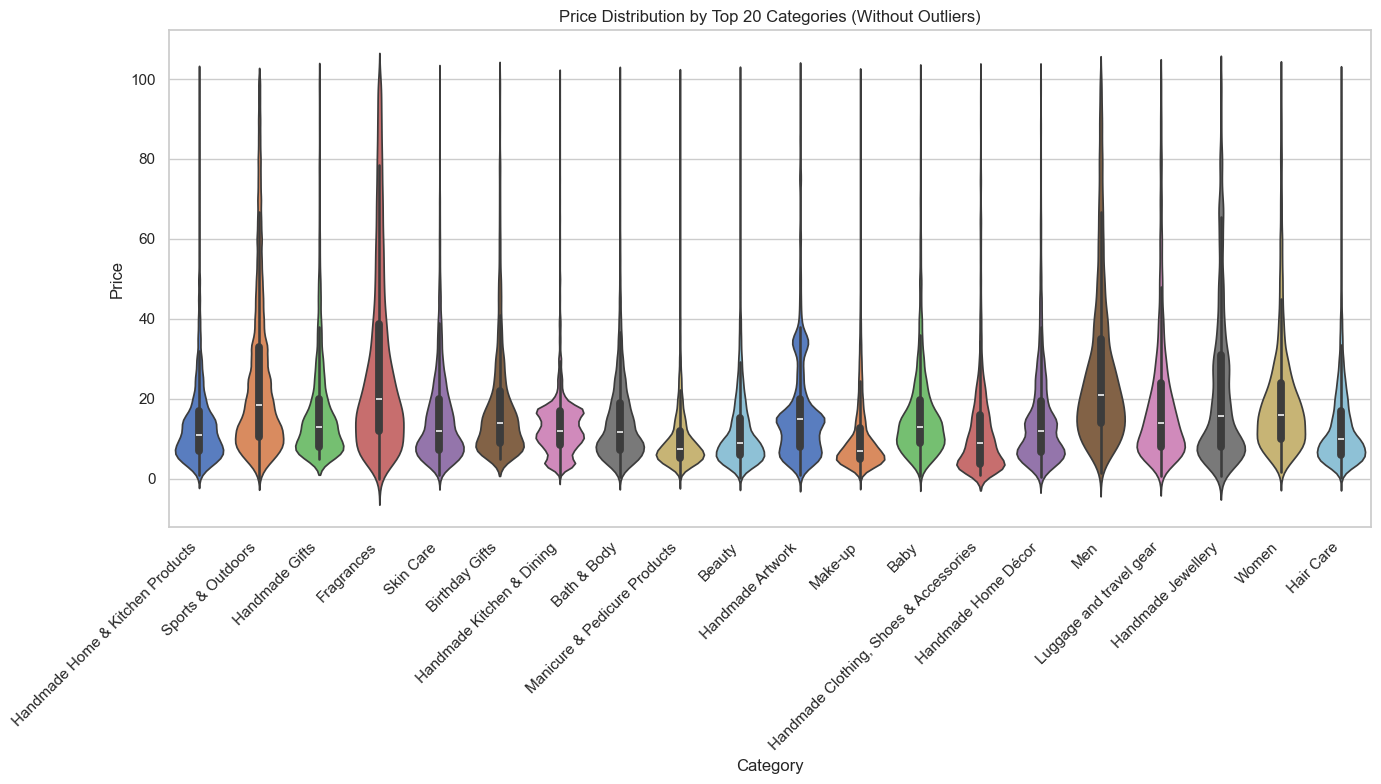

In [ ]:

# Top 20 categorías por conteo
top20_categories = df_filtered['category'].value_counts().head(20).index
df_top20 = df_filtered[df_filtered['category'].isin(top20_categories)]
# Violin plot
plt.figure(figsize=(14,8))
sns.violinplot(x='category', y='price', data=df_top20, palette='muted')
plt.title("Price Distribution by Top 20 Categories (Without Outliers)")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Fragrances tends to have the highest typical (median) price compared to the other categories shown.

In [22]:
#category with highest median price (no top filter)
median_prices = df_filtered.groupby('category')['price'].median()
highest_median_category = median_prices.idxmax()
highest_median_value = median_prices.max()
print("Category with highest median price:", highest_median_category)
print("Median price:", highest_median_value)

Category with highest median price: Desktop PCs
Median price: 74.0


Top 10 categories: Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')
El average price del top10 es: category
Sports & Outdoors                         25.17
Birthday Gifts                            18.60
Handmade Gifts                            17.40
Skin Care                                 15.65
Bath & Body                               14.68
Hair Care                                 13.46
Handmade Clothing, Shoes & Accessories    12.96
Beauty                                    12.52
Make-up                                   10.61
Manicure & Pedicure Products              10.23
Name: price, dtype: float64


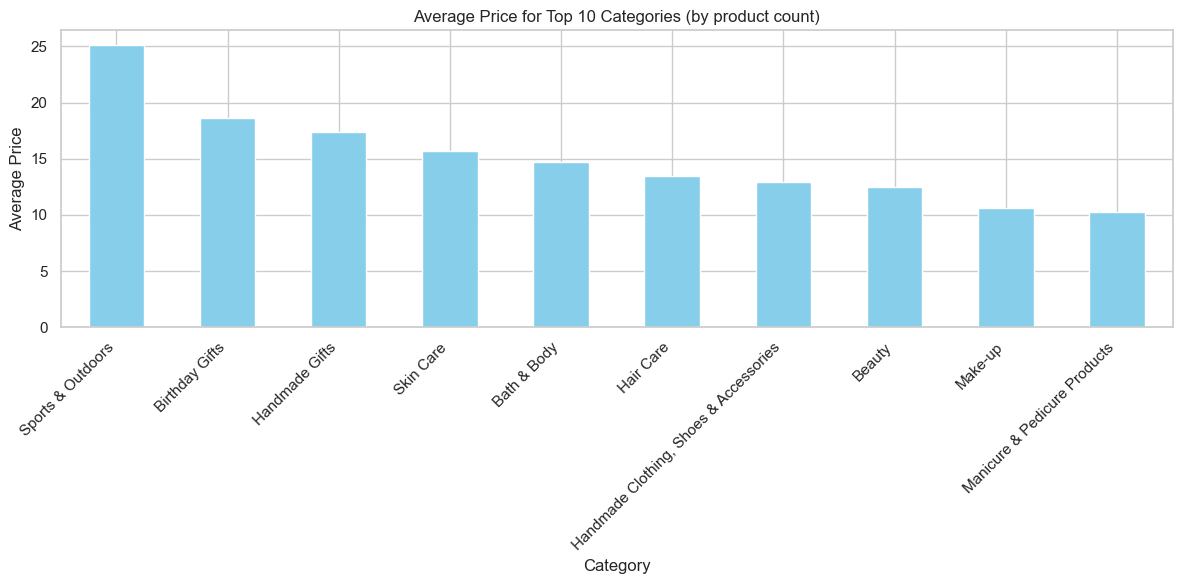

In [26]:
# 2) Bar Charts:
#    - Compare the average price of products for the top 10 categories (by count).
#    - Which category commands the highest average price? (No top filter here.)

top10_categories = (
    df_filtered['category']
    .value_counts()
    .head(10)
    .index
)
print(f'Top 10 categories:', top10_categories)
# Average price for top 10 categories
avg_price_top10 = (
    df_filtered[df_filtered['category'].isin(top10_categories)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)
print(f'El average price del top10 es:', round(avg_price_top10, 2))
#bar chart average price top 10 categories
plt.figure(figsize=(12,6))
avg_price_top10.plot(kind='bar', color='skyblue')
plt.title("Average Price for Top 10 Categories (by product count)")
plt.ylabel("Average Price")
plt.xlabel("Category")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [29]:
#category with highest average price (no top filter)
avg_prices_all = df_filtered.groupby('category')['price'].mean()
highest_avg_category = avg_prices_all.idxmax()
highest_avg_value = avg_prices_all.max()
print("Category with highest average price:", highest_avg_category)
print("Average price:", round(highest_avg_value,2))

Category with highest average price: Motherboards
Average price: 68.77


C:\Users\marta\AppData\Local\Temp\ipykernel_22600\1383046039.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='stars', data=df_top10_ratings, palette


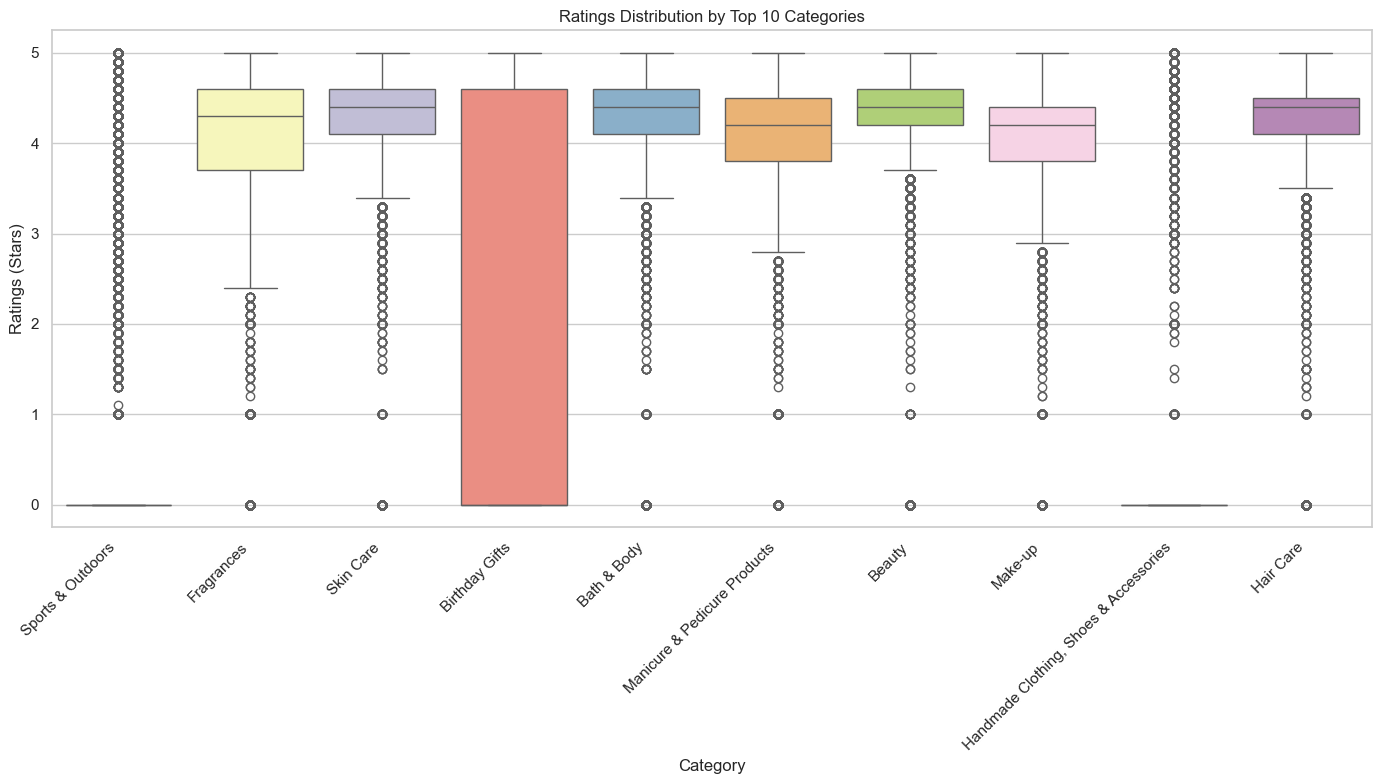

In [30]:
# 3) Box Plots:
#    - Visualize the distribution of product `ratings` (`stars`) by `category` using side-by-side box plots.
#    - Filter out the top 10 categories based on count for better visualization.
#    - Which category tends to receive the highest median rating? (No top filter here.)

top10_categories_ratings = df['category'].value_counts().head(10).index
df_top10_ratings = df[df['category'].isin(top10_categories_ratings)]
plt.figure(figsize=(14,8))
sns.boxplot(x='category', y='stars', data=df_top10_ratings, palette
='Set3')
plt.title("Ratings Distribution by Top 10 Categories")  
plt.xlabel("Category")
plt.ylabel("Ratings (Stars)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [33]:
#category with highest median rating (no top filter)
median_ratings = df_filtered.groupby('category')['stars'].median()
median_ratings.head()
highest_median_category = median_ratings.idxmax()
highest_median_value = median_ratings.max()
print("Category with highest median rating:", highest_median_category)
print("Median rating:", highest_median_value)

Category with highest median rating: Computer Memory
Median rating: 4.7


In [36]:
# Part 3: Investigating the Interplay Between Product Prices and Ratings
# Objective: Analyze how product ratings (`stars`) correlate with product prices.
# 1) Correlation Coefficients:
#    - Calculate the correlation coefficient between `price` and `stars`.
#    - Is there a significant correlation between product price and its rating?

correlation, p_value = pearsonr(df_filtered['price'], df_filtered['stars'])
print("Correlation coefficient between price and stars:", round(correlation, 2))



Correlation coefficient between price and stars: -0.08


The Pearson correlation between price and product rating is very weak (r = –0.08), indicating that price and rating are essentially unrelated. In practice, this means that more expensive products do not receive systematically higher or lower ratings than cheaper ones. Customer ratings appear to be influenced by factors other than price.

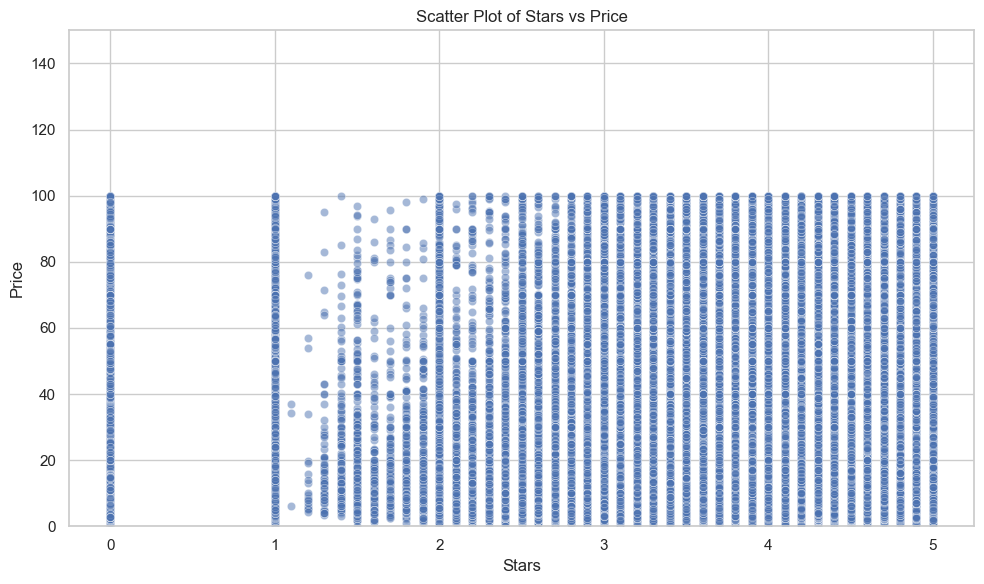

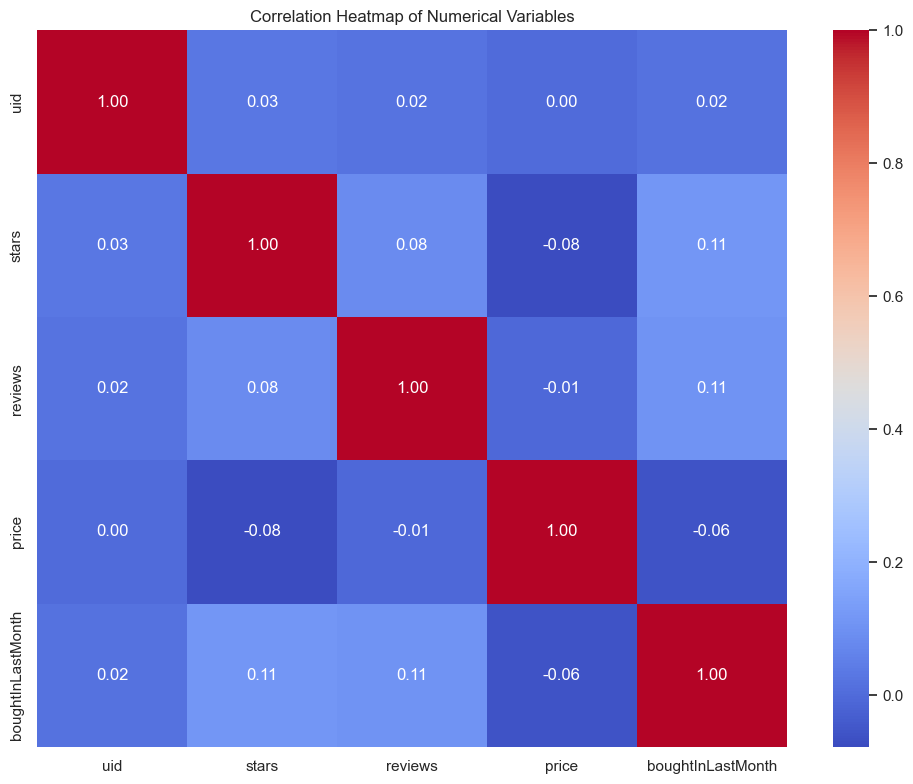

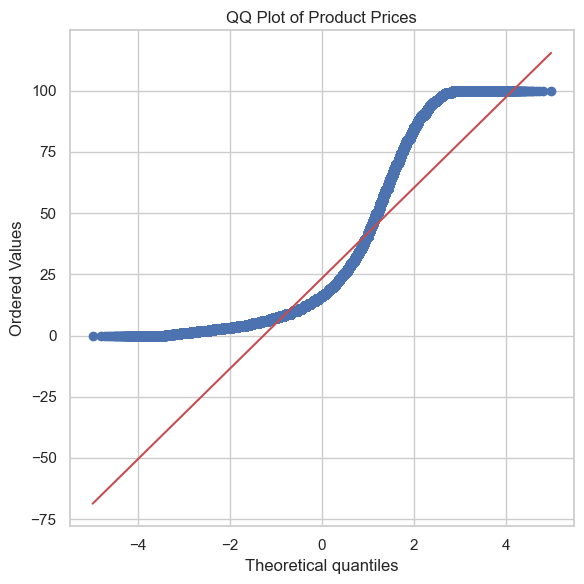

In [38]:
# 2) Visualizations:
#    - Scatter plot: `stars` vs `price` to observe patterns.
#    - Correlation heatmap: visualize correlations among numerical variables.
#    - QQ plot: examine if product prices follow a normal distribution.

plt.figure(figsize=(10,6))
sns.scatterplot(x='stars', y='price', data=df_filtered, alpha=0.5)
plt.title("Scatter Plot of Stars vs Price")
plt.xlabel("Stars")
plt.ylabel("Price")
plt.ylim(0,150)
plt.tight_layout()
plt.show()
# Correlation heatmap
numerical_cols = df_filtered.select_dtypes(include=[np.number]).columns
corr_matrix = df_filtered[numerical_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()
# QQ plot for price
plt.figure(figsize=(6,6))
probplot(df_filtered['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()


The QQ plot shows that product prices do not follow a normal distribution. The clear S-shaped pattern and the strong deviation from the reference line indicate pronounced skewness and non-normality. Prices are right-skewed, with a high concentration of low-priced products and a long upper tail driven by higher-priced items. Additionally, the flattening observed at the upper quantiles suggests a possible price ceiling or capped pricing structure in the dataset. Overall, this indicates that price variability is uneven and that median-based or non-parametric approaches are more appropriate than methods assuming normality.

In [39]:
#BONUS
#Do the same analysis without taking out the outliers. What are your insights?

correlation_all = df['price'].corr(df['stars'])
print("Coeficiente de correlación (price vs stars) sin eliminar outliers:", round(correlation_all, 3))


Coeficiente de correlación (price vs stars) sin eliminar outliers: -0.125


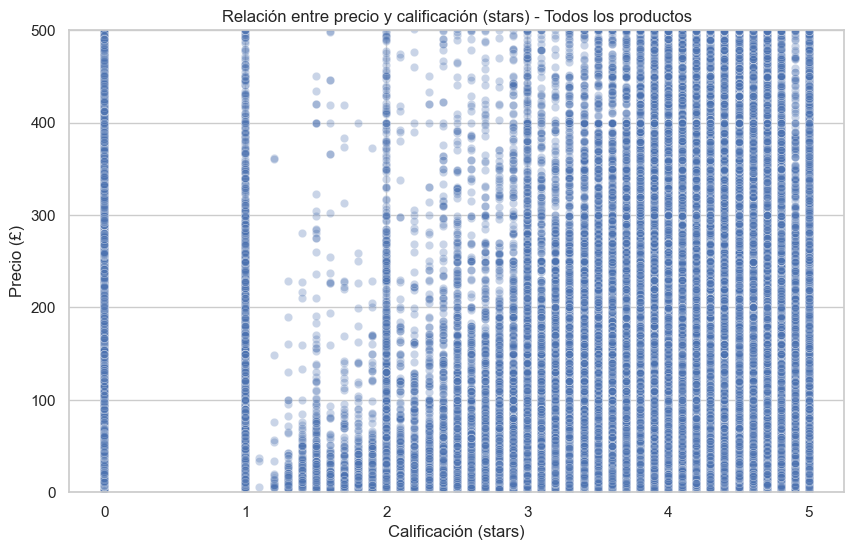

In [40]:
# Scatter plot sin eliminar outliers
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='stars', y='price', alpha=0.3)
plt.title("Relación entre precio y calificación (stars) - Todos los productos")
plt.xlabel("Calificación (stars)")
plt.ylabel("Precio (£)")
plt.ylim(0, 500)  # Puedes limitar el eje Y para mejor visualización
plt.show()

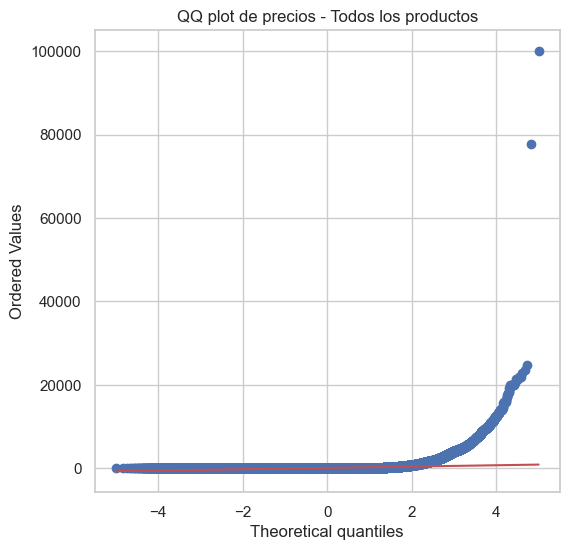

In [41]:
# QQ plot de precios sin eliminar outliers
import scipy.stats as stats
plt.figure(figsize=(6,6))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title("QQ plot de precios - Todos los productos")
plt.show()